0.08811652475060928 0.5399419795935432


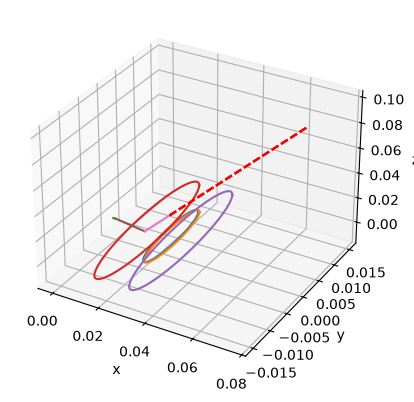

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

radius = 0.008
thetas = np.linspace(0, 2*np.pi, 201)
y_circle = radius * np.cos(thetas)
z_circle = radius * np.sin(thetas)

plate_1_x = 0.025
separation = 0.0005
plate_2_x = plate_1_x + separation

# plot the two circular plates
ax.plot(np.full_like(thetas, plate_1_x), y_circle, z_circle)
ax.plot(np.full_like(thetas, plate_2_x), y_circle, z_circle)

def reflection(x, y, z, theta, phi):
    rho = np.linspace(0, 5, 1000)

    midpoint = plate_1_x + separation/2

    # moving to the right
    if x < midpoint:
        x_light = x + rho * np.cos(theta) * np.sin(phi)
        y_light = y + rho * np.sin(theta) * np.sin(phi)
        z_light = z + rho * np.cos(phi)

        mask = x_light <= plate_2_x
        ax.plot(x_light[mask], y_light[mask], z_light[mask])

        idx = np.where(mask)[0][-1]
        
        return x_light[idx], y_light[idx], z_light[idx]

    # moving to the left
    else:
        x_light = x - rho * np.cos(theta) * np.sin(phi)
        y_light = y + rho * np.sin(theta) * np.sin(phi)
        z_light = z + rho * np.cos(phi)

        mask = x_light >= plate_1_x
        ax.plot(x_light[mask], y_light[mask], z_light[mask])

        idx = np.where(mask)[0][-1]
        return x_light[idx], y_light[idx], z_light[idx]

def fp(x0, y0, z0, theta, phi, n_reflections=6):
    # source point
    #ax.scatter(x0, y0, z0, s=40)

    rho = np.linspace(0, 10, 10000)

    x_light = x0 + rho * np.cos(theta) * np.sin(phi)
    y_light = y0 + rho * np.sin(theta) * np.sin(phi)
    z_light = z0 + rho * np.cos(phi)

    # first segment up to first plate
    mask = x_light <= plate_1_x
    ax.plot(x_light[mask], y_light[mask], z_light[mask])

    idx = np.where(mask)[0][-1]
    x_ref = x_light[idx]
    y_ref = y_light[idx]
    z_ref = z_light[idx]

    # repeated reflections
    for _ in range(n_reflections):
        x_ref, y_ref, z_ref = reflection(x_ref, y_ref, z_ref, theta, phi)
        rho_out = np.linspace(0, 0.1, 1000)

        x_out = x_ref + rho_out * np.cos(theta) * np.sin(phi)
        y_out = y_ref + rho_out * np.sin(theta) * np.sin(phi)
        z_out = z_ref + rho_out * np.cos(phi)

        ax.plot(x_out, y_out, z_out, '--', alpha=0.7, color = 'red')
    

#fp(0, 0, 0, 0.1, np.pi/2)
#fp(2, -0.5, 0.1, np.pi/2 - 0.1)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

#ax.view_init(0,0,0)

ax.plot(np.linspace(-0.001,0,100), np.linspace(0,0,100), np.linspace(0,0,100))

rays = 1

y_arr = []
z_arr = []
theta_arr = []
phi_arr = []

for i in range(rays):
    
    y_arr.append(random.uniform(-33.5e-6, 33.5e-6))
    z_arr.append(random.uniform(-33.5e-6, 33.5e-6))
    theta_arr.append(random.uniform(0.2,-0.2))
    phi_arr.append(random.uniform(np.pi/2 + 0.21,np.pi/2 - 0.21))

    
lens_1_x = 0.015
lens_2_x = 0.03

radius = 0.015
y_circle = radius * np.cos(thetas)
z_circle = radius * np.sin(thetas)

ax.plot(np.full_like(thetas, lens_1_x), y_circle, z_circle)
ax.plot(np.full_like(thetas, lens_2_x), y_circle, z_circle)

def tolens(x0, y0, z0, theta, phi):
    rho = np.linspace(0, 1, 10000)

    x_light = rho * np.cos(theta) * np.sin(phi)
    y_light = y0 + rho * np.sin(theta) * np.sin(phi)
    z_light = z0 + rho * np.cos(phi)

    
    mask = x_light <= lens_1_x
    ax.plot(x_light[mask], y_light[mask], z_light[mask])

    idx = np.where(mask)[0][-1]
    x_ref = x_light[idx]
    y_ref = y_light[idx]
    z_ref = z_light[idx]
    
    return lens_1_x, y_ref, z_ref, (np.sqrt(y_ref**2 + z_ref**2) / 0.015), (np.pi/2 + (np.arctan(y_ref / z_ref)))


for i in range(rays):
    x, y, z, theta, phi = tolens(0, y_arr[i], z_arr[i], theta_arr[i], phi_arr[i])
    print(theta, phi)
    fp(x, y, z, theta, phi)
    
    

0.015415788362782061 3.7706631062808293


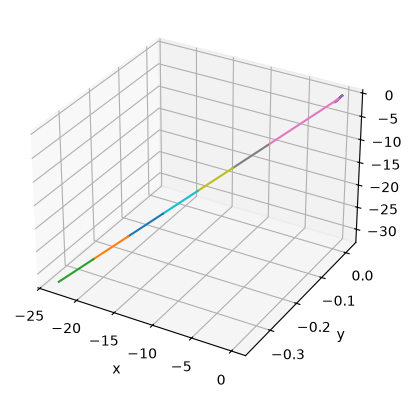

In [2]:

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

radius = 0.008
thetas = np.linspace(0, 2*np.pi, 201)
y_circle = radius * np.cos(thetas)
z_circle = radius * np.sin(thetas)

plate_1_x = 0.025
separation = 0.0005
plate_2_x = plate_1_x + separation

# plot the two circular plates
ax.plot(np.full_like(thetas, plate_1_x), y_circle, z_circle)
ax.plot(np.full_like(thetas, plate_2_x), y_circle, z_circle)

def reflection(x, y, z, theta, phi):
    rho = np.linspace(0, 5, 1000)
    midpoint = plate_1_x + separation / 2

    # moving to the right
    if x < midpoint:
        x_light = x + rho * np.cos(theta) * np.sin(phi)
        y_light = y + rho * np.sin(theta) * np.sin(phi)
        z_light = z + rho * np.cos(phi)

        mask = x_light <= plate_2_x
        ax.plot(x_light[mask], y_light[mask], z_light[mask])

        idx = np.where(mask)[0][-1]
        return x_light[idx], y_light[idx], z_light[idx]

    # moving to the left
    else:
        x_light = x - rho * np.cos(theta) * np.sin(phi)
        y_light = y + rho * np.sin(theta) * np.sin(phi)
        z_light = z + rho * np.cos(phi)

        mask = x_light >= plate_1_x
        ax.plot(x_light[mask], y_light[mask], z_light[mask])

        idx = np.where(mask)[0][-1]
        return x_light[idx], y_light[idx], z_light[idx]

def fp(x0, y0, z0, theta, phi, n_reflections=6):
    rho = np.linspace(0, 10, 10000)

    x_light = x0 + rho * np.cos(theta) * np.sin(phi)
    y_light = y0 + rho * np.sin(theta) * np.sin(phi)
    z_light = z0 + rho * np.cos(phi)

    # first segment up to first plate
    mask = x_light <= plate_1_x
    ax.plot(x_light[mask], y_light[mask], z_light[mask])

    idx = np.where(mask)[0][-1]
    x_ref = x_light[idx]
    y_ref = y_light[idx]
    z_ref = z_light[idx]

    # repeated reflections
    for _ in range(n_reflections):
        x_ref, y_ref, z_ref = reflection(x_ref, y_ref, z_ref, theta, phi)

        rho_out = np.linspace(0, 0.02, 300)
        x_out = x_ref + rho_out * np.cos(theta) * np.sin(phi)
        y_out = y_ref + rho_out * np.sin(theta) * np.sin(phi)
        z_out = z_ref + rho_out * np.cos(phi)

        ax.plot(x_out, y_out, z_out, '--', alpha=0.7, color='red')

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.plot(np.linspace(-0.001, 0, 100), np.zeros(100), np.zeros(100))

rays = 1

y_arr = []
z_arr = []
theta_arr = []
phi_arr = []

for i in range(rays):
    y_arr.append(random.uniform(-33.5e-6, 33.5e-6))
    z_arr.append(random.uniform(-33.5e-6, 33.5e-6))
    theta_arr.append(random.uniform(-0.2, 0.2))
    phi_arr.append(random.uniform(np.pi/2 - 0.21, np.pi/2 + 0.21))

lens_1_x = 0.015
lens_2_x = 0.03

radius = 0.015
y_circle = radius * np.cos(thetas)
z_circle = radius * np.sin(thetas)

ax.plot(np.full_like(thetas, lens_1_x), y_circle, z_circle)
ax.plot(np.full_like(thetas, lens_2_x), y_circle, z_circle)

def tolens(x0, y0, z0, theta, phi):
    rho = np.linspace(0, 1, 10000)

    x_light = x0 + rho * np.cos(theta) * np.sin(phi)
    y_light = y0 + rho * np.sin(theta) * np.sin(phi)
    z_light = z0 + rho * np.cos(phi)

    mask = x_light <= lens_1_x
    ax.plot(x_light[mask], y_light[mask], z_light[mask])

    idx = np.where(mask)[0][-1]
    x_ref = x_light[idx]
    y_ref = y_light[idx]
    z_ref = z_light[idx]

    r_perp = np.sqrt(y_ref**2 + z_ref**2)

    # toy model: larger distance from axis -> larger bend
    new_theta = r_perp / 0.015
    new_phi = np.pi/2 + np.arctan2(y_ref, z_ref)

    return lens_1_x, y_ref, z_ref, new_theta, new_phi

for i in range(rays):
    x, y, z, theta, phi = tolens(0, y_arr[i], z_arr[i], theta_arr[i], phi_arr[i])
    print(theta, phi)
    fp(x, y, z, theta, phi)

plt.show()

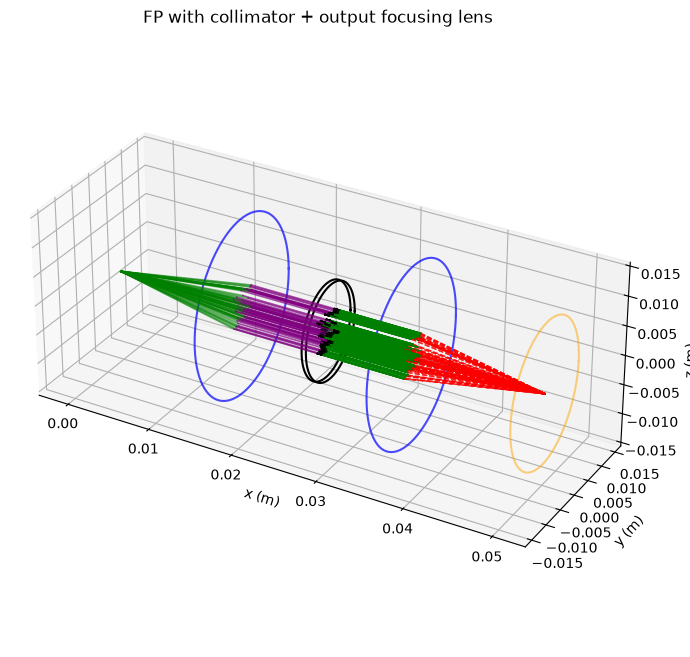

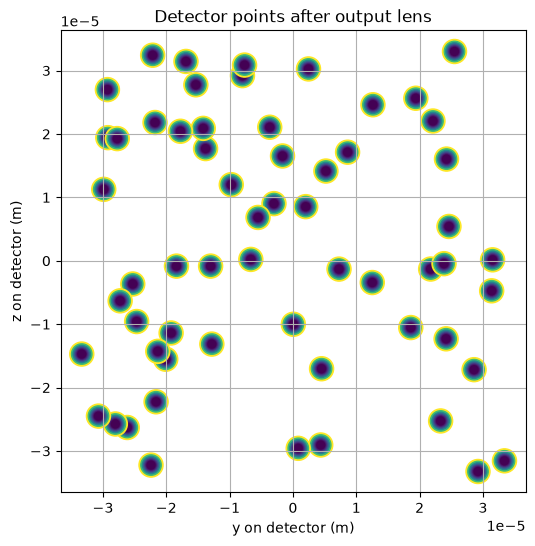

In [3]:

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

lens_radius = 0.015
plate_radius = 0.008

source_x = 0.0

lens_1_x = 0.015
f_lens_1 = lens_1_x - source_x

plate_1_x = 0.025
separation = 0.0005
plate_2_x = plate_1_x + separation

lens_2_x = 0.035
f_lens_2 = f_lens_1
detector_x = lens_2_x + f_lens_2


T_lens_1 = 0.92
T_lens_2 = 0.92
R_fp = 0.85
T_fp = 1.0 - R_fp


circle_t = np.linspace(0, 2*np.pi, 300)

def draw_circle_xplane(x0, radius, colour='k', alpha=1.0):
    y = radius * np.cos(circle_t)
    z = radius * np.sin(circle_t)
    x = np.full_like(circle_t, x0)
    ax.plot(x, y, z, color=colour, alpha=alpha)
    

draw_circle_xplane(lens_1_x, lens_radius, colour='blue', alpha=0.7)
draw_circle_xplane(plate_1_x, plate_radius, colour='black')
draw_circle_xplane(plate_2_x, plate_radius, colour='black')
draw_circle_xplane(lens_2_x, lens_radius, colour='blue', alpha=0.7)
draw_circle_xplane(detector_x, 0.012, colour='orange', alpha=0.5)

ax.text(plate_1_x, 0, plate_radius + 0.35, "Mirror 1")
ax.text(plate_2_x, 0, plate_radius + 0.35, "Mirror 2")
ax.text(lens_1_x, 0, lens_radius + 0.35, "Collimating Lens")
ax.text(lens_1_x, 0, lens_radius + 0.35, "Focusing Lens")
ax.text(detector_x, 0, 0.012 + 0.35, "Detector")

ax.plot(np.linspace(0, detector_x, 400), np.zeros(400), np.zeros(400), color='grey', alpha=0.4)


def normalise(v):
    v = np.array(v, dtype=float)
    return v / np.linalg.norm(v)

def propagate_to_x_plane(r0, d, x_plane):
    if abs(d[0]) < 1e-14:
        return None, None
    s = (x_plane - r0[0]) / d[0]
    if s < 0:
        return None, None
    r_hit = r0 + s * d
    return r_hit, s

def plot_segment(r0, r1, style='-', colour=None, alpha=1.0, lw=1.2):
    ax.plot([r0[0], r1[0]], [r0[1], r1[1]], [r0[2], r1[2]], style, color=colour, alpha=alpha, lw=lw)

def inside_circular_aperture(r, radius):
    return r[1]**2 + r[2]**2 <= radius**2


def make_ray_from_angles(theta, phi):
    dx = np.cos(theta) * np.sin(phi)
    dy = np.sin(theta) * np.sin(phi)
    dz = np.cos(phi)
    return normalise([dx, dy, dz])


def pass_through_collimator(r0, d, lens_x, aperture_radius, f_lens, intensity):
    r_hit, s = propagate_to_x_plane(r0, d, lens_x)
    if r_hit is None:
        return None, None, None
    if not inside_circular_aperture(r_hit, aperture_radius):
        return None, None, None

    plot_segment(r0, r_hit, colour='green', alpha=0.6)

    y0 = r0[1]
    z0 = r0[2]

    d_out = normalise([f_lens, -y0, -z0])
    intensity_out = intensity * T_lens_1

    return r_hit, d_out, intensity_out

def focus_with_lens_2(r_in, d_in, lens_x, aperture_radius, f_lens, intensity):
    r_lens, s = propagate_to_x_plane(r_in, d_in, lens_x)
    if r_lens is None:
        return None, None, None
    if not inside_circular_aperture(r_lens, aperture_radius):
        return None, None, None

    plot_segment(r_in, r_lens, colour='green', alpha=0.6)

    # detector is in back focal plane of lens 2
    y_det = -f_lens * (d_in[1] / d_in[0])
    z_det = -f_lens * (d_in[2] / d_in[0])
    r_det = np.array([lens_x + f_lens, y_det, z_det])

    intensity_out = intensity * T_lens_2

    return r_lens, r_det, intensity_out


detector_hits = []

def trace_fp_with_output_lens(r0, d, intensity, n_bounces=8):
    r_hit_1, s1 = propagate_to_x_plane(r0, d, plate_1_x)
    if r_hit_1 is None:
        return
    if not inside_circular_aperture(r_hit_1, plate_radius):
        return

    plot_segment(r0, r_hit_1, colour='purple', alpha=0.7)

    # transmission into cavity through first plate
    cavity_intensity = intensity * T_fp

    r_current = r_hit_1.copy()
    d_current = d.copy()

    for n in range(n_bounces):
        # travel to second plate
        r_next, s_next = propagate_to_x_plane(r_current, d_current, plate_2_x)
        if r_next is None:
            break
        if not inside_circular_aperture(r_next, plate_radius):
            break

        plot_segment(r_current, r_next, colour='black', alpha=0.8)

        # transmitted out of second plate
        transmitted_intensity = cavity_intensity * T_fp

        # send transmitted beam through second lens
        result = focus_with_lens_2(r_next, d_current, lens_2_x, lens_radius, f_lens_2, transmitted_intensity)
        if result[0] is not None:
            r_lens2, r_det, I_det = result
            plot_segment(r_lens2, r_det, style='--', colour='red', alpha=min(1.0, 0.2 + 3.0 * I_det), lw=1.0)
            detector_hits.append((r_det[1], r_det[2], I_det))

        # reflected part remains in cavity
        cavity_intensity = cavity_intensity * R_fp

        # reflect at second plate: flip x component
        d_reflected = np.array([-d_current[0], d_current[1], d_current[2]])

        # go back to first plate
        r_back, s_back = propagate_to_x_plane(r_next, d_reflected, plate_1_x)
        if r_back is None:
            break
        if not inside_circular_aperture(r_back, plate_radius):
            break

        plot_segment(r_next, r_back, colour='black', alpha=0.8)

        cavity_intensity = cavity_intensity * R_fp

        # reflect again from first plate so beam heads rightward once more
        d_current = np.array([-d_reflected[0], d_reflected[1], d_reflected[2]])
        r_current = r_back.copy()


rays = 60
core_radius = 33.5e-6

y_arr = []
z_arr = []
theta_arr = []
phi_arr = []

for i in range(rays):
    y_arr.append(random.uniform(-core_radius, core_radius))
    z_arr.append(random.uniform(-core_radius, core_radius))
    theta_arr.append(random.uniform(-0.2, 0.2))
    phi_arr.append(random.uniform(np.pi/2 - 0.2, np.pi/2 + 0.2))

for i in range(rays):
    r0 = np.array([source_x, y_arr[i], z_arr[i]])
    d0 = make_ray_from_angles(theta_arr[i], phi_arr[i])
    I0 = 1.0

    result = pass_through_collimator(r0, d0, lens_1_x, lens_radius, f_lens_1, I0)
    if result[0] is None:
        continue

    r1, d1, I1 = result
    trace_fp_with_output_lens(r1, d1, I1, n_bounces=8)


ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_zlabel("z (m)")
ax.set_title("FP with collimator + output focusing lens")
ax.set_box_aspect([4, 1.5, 1.5])

plt.show()


if len(detector_hits) > 0:
    y_det = np.array([hit[0] for hit in detector_hits])
    z_det = np.array([hit[1] for hit in detector_hits])
    I_det = np.array([hit[2] for hit in detector_hits])
    
    hit_rad = np.sqrt(y_det**2 + y_det**2)

    plt.figure(figsize=(6, 6))
    plt.scatter(y_det, z_det, s=300 * I_det / np.max(I_det), c=I_det)
    plt.xlabel("y on detector (m)")
    plt.ylabel("z on detector (m)")
    plt.title("Detector points after output lens")
    plt.axis("equal")
    plt.grid()
    plt.show()



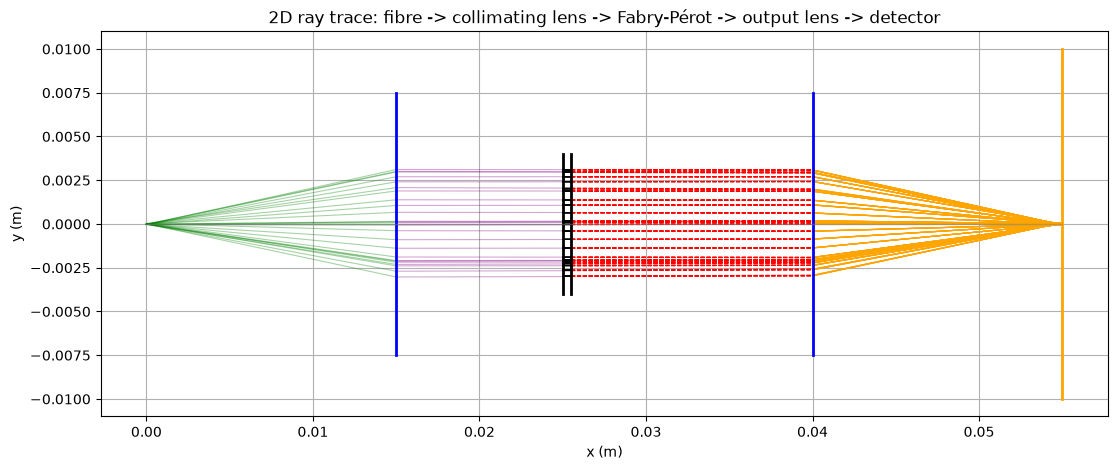

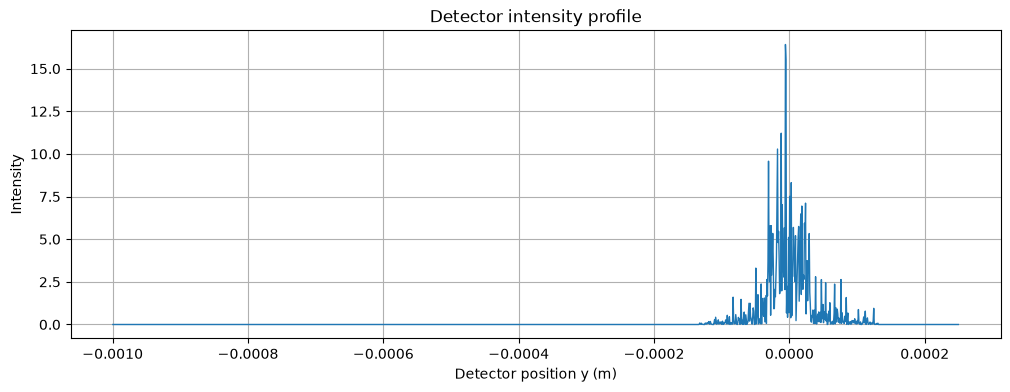

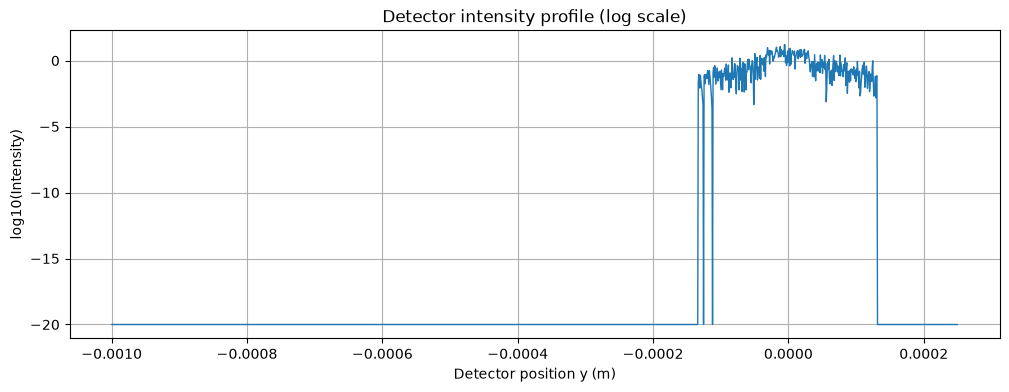

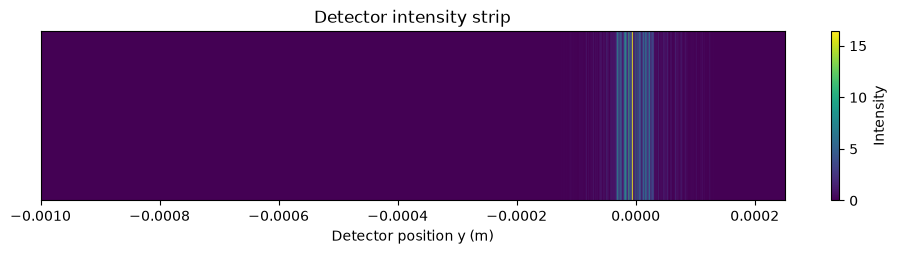

In [4]:
np.random.seed(42)

n_rays = 1000
n_terms = 20

wavelength = 577e-9
cavity_index = 1.0

fibre_radius = 33.5e-6
source_angle_max = 0.22

f1 = 0.015
f2 = 0.015

source_x = 0.0
lens1_x = 0.015
plate1_x = 0.025
separation = 0.0005
plate2_x = plate1_x + separation
lens2_x = 0.040
detector_x = 0.055

lens_radius = 0.015 / 2
plate_radius = 0.004

R_lens = 0.05

T_lens1 = 0.99
T_lens2 = 0.99
R_fp = 0.85
T_fp = 1.0 - R_fp

r_fp = np.sqrt(R_fp)
t_fp = np.sqrt(T_fp)


def propagate_ray(x0, y0, theta0, x1):
    y1 = y0 + (x1 - x0) * np.tan(theta0)
    return y1

def thin_lens(theta_in, y_at_lens, f):
    return theta_in - y_at_lens / f

def inside_aperture(y, radius):
    return np.abs(y) <= radius

def phase_difference(theta, n, d, wavelength):
    cos_theta = np.cos(theta)
    return 4 * np.pi * n * d * cos_theta / wavelength


detector_hits_y = []
detector_hits_E = []

# for drawing only a subset so the plot stays readable
draw_limit = 25


plt.figure(figsize=(13, 5))

for i in range(n_rays):
    # source ray from fibre face
    y0 = np.random.uniform(-fibre_radius, fibre_radius)
    theta0 = np.random.uniform(-source_angle_max, source_angle_max)
    E0 = 1.0 + 0.0j

    # propagate source -> lens 1
    y_l1 = propagate_ray(source_x, y0, theta0, lens1_x)
    if not inside_aperture(y_l1, lens_radius):
        continue

    theta_after_l1 = thin_lens(theta0, y_l1, f1)
    E_after_l1 = E0 * np.sqrt(T_lens1)

    if i < draw_limit:
        plt.plot([source_x, lens1_x], [y0, y_l1], color='green', alpha=0.35, lw=0.8)

    # propagate lens 1 -> plate 1
    y_p1 = propagate_ray(lens1_x, y_l1, theta_after_l1, plate1_x)
    if not inside_aperture(y_p1, plate_radius):
        continue

    if i < draw_limit:
        plt.plot([lens1_x, plate1_x], [y_l1, y_p1], color='purple', alpha=0.35, lw=0.8)

    delta = phase_difference(theta_after_l1, cavity_index, separation, wavelength)

    # multiple transmitted beams
    for m in range(n_terms):
        # forward pass inside cavity to plate 2
        y_p2 = propagate_ray(plate1_x, y_p1, theta_after_l1, plate2_x)
        if not inside_aperture(y_p2, plate_radius):
            break

        if i < draw_limit:
            plt.plot([plate1_x, plate2_x], [y_p1, y_p2], color='black', alpha=0.25, lw=0.7)

        # transmitted field through FP after m round trips
        E_trans = E_after_l1 * (t_fp ** 2) * (r_fp ** (2 * m)) * np.exp(1j * m *  delta)

        # propagate plate 2 -> lens 2
        y_l2 = propagate_ray(plate2_x, y_p2, theta_after_l1, lens2_x)
        if not inside_aperture(y_l2, lens_radius):
            break

        if i < draw_limit:
            plt.plot([plate2_x, lens2_x], [y_p2, y_l2], '--', color='red', alpha=0.30, lw=0.8)

        # refract at lens 2 physically
        theta_after_l2 = thin_lens(theta_after_l1, y_l2, f2)
        E_after_l2 = E_trans * np.sqrt(T_lens2)

        # propagate lens 2 -> detector
        y_det = propagate_ray(lens2_x, y_l2, theta_after_l2, detector_x)
        

        detector_hits_y.append(y_det)
        detector_hits_E.append(E_after_l2)

        if i < draw_limit:
            plt.plot([lens2_x, detector_x], [y_l2, y_det], color='orange', alpha=0.30, lw=0.8)

        # one round trip inside cavity before next transmitted beam
        y_back_p1 = propagate_ray(plate2_x, y_p2, -theta_after_l1, plate1_x)
        if not inside_aperture(y_back_p1, plate_radius):
            break

        if i < draw_limit:
            plt.plot([plate2_x, plate1_x], [y_p2, y_back_p1], color='black', alpha=0.20, lw=0.7)

        y_p1 = y_back_p1


plt.plot([lens1_x, lens1_x], [-lens_radius, lens_radius], color='blue', lw=2)
plt.plot([plate1_x, plate1_x], [-plate_radius, plate_radius], color='black', lw=2)
plt.plot([plate2_x, plate2_x], [-plate_radius, plate_radius], color='black', lw=2)
plt.plot([lens2_x, lens2_x], [-lens_radius, lens_radius], color='blue', lw=2)
plt.plot([detector_x, detector_x], [-0.01, 0.01], color='orange', lw=2)
plt.plot([source_x, detector_x], [0, 0], color='grey', alpha=0.5, lw=1)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("2D ray trace: fibre -> collimating lens -> Fabry-Pérot -> output lens -> detector")
plt.grid()
plt.show()

detector_hits_y = np.array(detector_hits_y)
detector_hits_E = np.array(detector_hits_E, dtype=complex)

y_min = -0.001
y_max = 0.00025
n_pixels = 1600
y_edges = np.linspace(y_min, y_max, n_pixels + 1)
y_centres = 0.5 * (y_edges[:-1] + y_edges[1:])

field_grid = np.zeros(n_pixels, dtype=complex)
pix = np.digitize(detector_hits_y, y_edges) - 1
valid = (pix >= 0) & (pix < n_pixels)

for p, E in zip(pix[valid], detector_hits_E[valid]):
    field_grid[p] += E

intensity = np.abs(field_grid) ** 2

plt.figure(figsize=(12, 4))
plt.plot(y_centres, intensity, lw=1)
plt.xlabel("Detector position y (m)")
plt.ylabel("Intensity")
plt.title("Detector intensity profile")
plt.grid()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(y_centres, np.log10(intensity + 1e-20), lw=1)
plt.xlabel("Detector position y (m)")
plt.ylabel("log10(Intensity)")
plt.title("Detector intensity profile (log scale)")
plt.grid()
plt.show()

plt.figure(figsize=(12, 2.2))
plt.imshow(intensity[np.newaxis, :], extent=[y_min, y_max, 0, 1], origin='lower', aspect='auto')
plt.xlabel("Detector position y (m)")
plt.yticks([])
plt.title("Detector intensity strip")
plt.colorbar(label="Intensity")
plt.show()



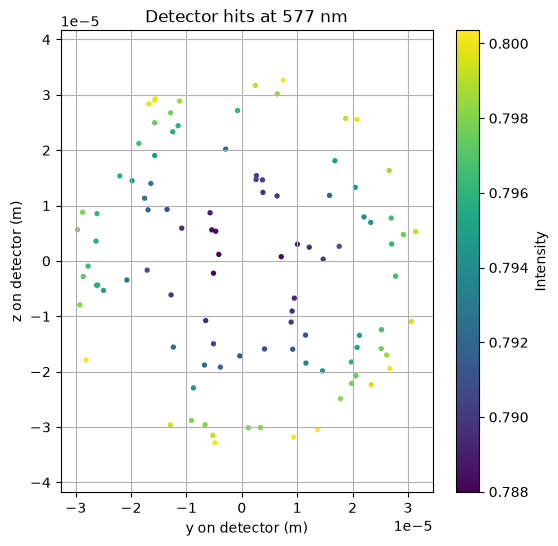

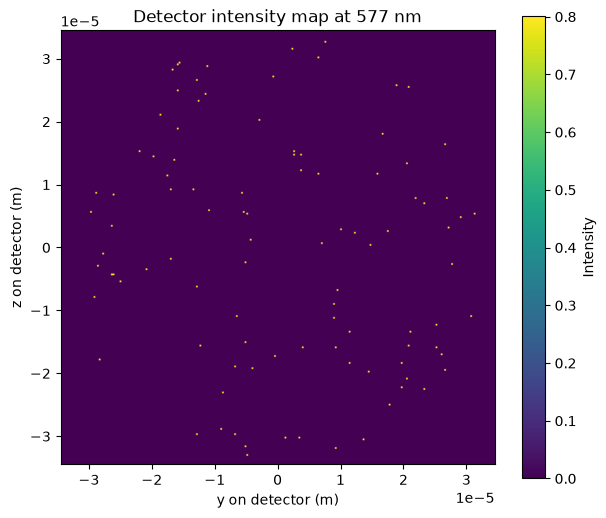

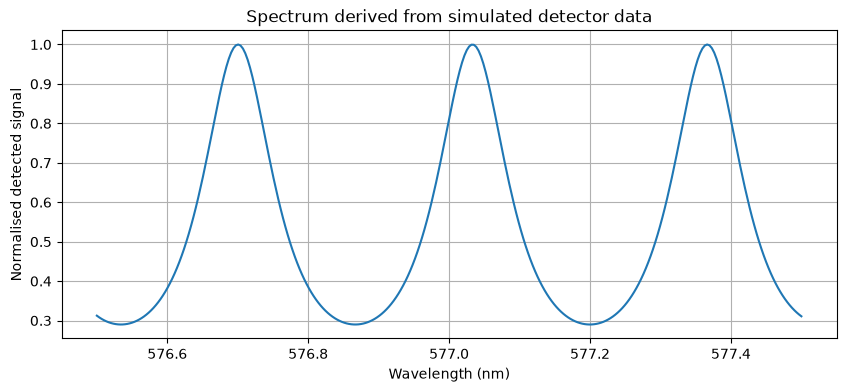

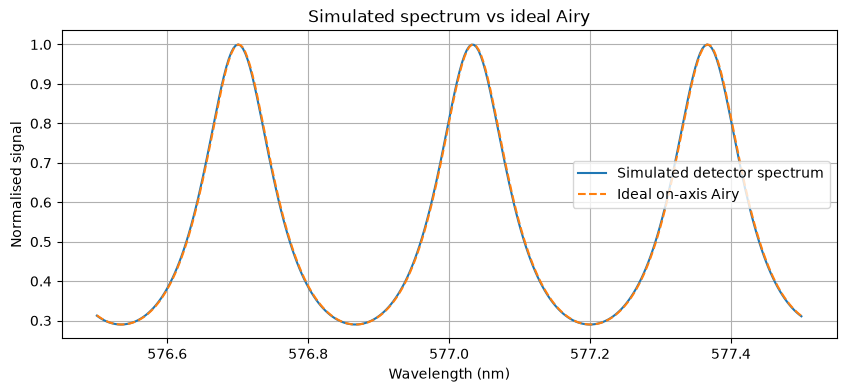

Detected rays at 577 nm: 100
Total detector intensity at 577 nm: 79.481
FSR = 300.000 GHz
FSR = 0.3329 nm
Finesse = 2.46
Estimated FWHM = 135.438 pm


In [5]:
random.seed(42)
np.random.seed(42)

wavelength0 = 577e-9
cavity_index = 1.0
R_fp = 0.3

source_x = 0.0
lens_1_x = 0.015
f_lens_1 = lens_1_x - source_x

plate_1_x = 0.025
separation = 0.0005
plate_2_x = plate_1_x + separation

lens_2_x = 0.035
f_lens_2 = f_lens_1
detector_x = lens_2_x + f_lens_2

lens_radius = 13.5e-3 / 2
plate_radius = 0.008

T_lens_1 = 0.99
T_lens_2 = 0.99

core_radius = 33.5e-6
fiber_NA = 0.22
theta_max = np.arcsin(fiber_NA)

n_rays = 100


def normalise(v):
    v = np.array(v, dtype=float)
    n = np.linalg.norm(v)
    if n == 0:
        return v
    return v / n

def make_ray_from_angles(theta, phi):
    dx = np.cos(theta)
    dy = np.sin(theta) * np.cos(phi)
    dz = np.sin(theta) * np.sin(phi)
    return normalise([dx, dy, dz])

def propagate_to_x_plane(r0, d, x_plane):
    if abs(d[0]) < 1e-14:
        return None
    s = (x_plane - r0[0]) / d[0]
    if s < 0:
        return None
    return r0 + s * d

def inside_circular_aperture(r, radius):
    return r[1]**2 + r[2]**2 <= radius**2

def ray_angle_to_axis(d):
    d = normalise(d)
    return np.arccos(np.clip(d[0], -1.0, 1.0))

def airy_transmission(wavelength, theta, n, d, R):
    F = 4 * R / (1 - R)**2
    delta = 4 * np.pi * n * d * np.cos(theta) / wavelength
    return 1 / (1 + F * np.sin(delta / 2)**2)


ray_starts = []

for _ in range(n_rays):
    while True:
        y0 = random.uniform(-core_radius, core_radius)
        z0 = random.uniform(-core_radius, core_radius)
        if y0**2 + z0**2 <= core_radius**2:
            break

    theta0 = theta_max * np.sqrt(random.random())
    phi0 = random.uniform(0, 2*np.pi)

    r0 = np.array([source_x, y0, z0])
    d0 = make_ray_from_angles(theta0, phi0)
    ray_starts.append((r0, d0))


def simulate_system(wavelength):
    detector_hits = []
    total_intensity = 0.0

    for r0, d0 in ray_starts:
        I = 1.0

        # propagate to lens 1
        r_l1 = propagate_to_x_plane(r0, d0, lens_1_x)
        if r_l1 is None or not inside_circular_aperture(r_l1, lens_radius):
            continue

        # ideal collimator: output direction set by source position
        d1 = normalise([f_lens_1, -r0[1], -r0[2]])
        I *= T_lens_1

        # to plate 1
        r_p1 = propagate_to_x_plane(r_l1, d1, plate_1_x)
        if r_p1 is None or not inside_circular_aperture(r_p1, plate_radius):
            continue

        # to plate 2
        r_p2 = propagate_to_x_plane(r_p1, d1, plate_2_x)
        if r_p2 is None or not inside_circular_aperture(r_p2, plate_radius):
            continue

        # FP Airy transmission
        theta_cavity = ray_angle_to_axis(d1)
        T_airy = airy_transmission(wavelength, theta_cavity, cavity_index, separation, R_fp)
        I *= T_airy

        # to lens 2
        r_l2 = propagate_to_x_plane(r_p2, d1, lens_2_x)
        if r_l2 is None or not inside_circular_aperture(r_l2, lens_radius):
            continue

        # detector in back focal plane of lens 2
        y_det = -f_lens_2 * (d1[1] / d1[0])
        z_det = -f_lens_2 * (d1[2] / d1[0])
        r_det = np.array([detector_x, y_det, z_det])

        I *= T_lens_2

        detector_hits.append((r_det[1], r_det[2], I))
        total_intensity += I

    return detector_hits, total_intensity


detector_hits, total_I_577 = simulate_system(wavelength0)

if len(detector_hits) == 0:
    print("No rays reached the detector.")
else:
    y_det = np.array([h[0] for h in detector_hits])
    z_det = np.array([h[1] for h in detector_hits])
    I_det = np.array([h[2] for h in detector_hits])

    plt.figure(figsize=(6, 6))
    plt.scatter(y_det, z_det, c=I_det, s=8)
    plt.xlabel("y on detector (m)")
    plt.ylabel("z on detector (m)")
    plt.title("Detector hits at 577 nm")
    plt.axis("equal")
    plt.grid()
    plt.colorbar(label="Intensity")
    plt.show()

    n_pix = 250
    lim = max(np.max(np.abs(y_det)), np.max(np.abs(z_det))) * 1.05
    y_edges = np.linspace(-lim, lim, n_pix + 1)
    z_edges = np.linspace(-lim, lim, n_pix + 1)

    image, _, _ = np.histogram2d(y_det, z_det, bins=[y_edges, z_edges], weights=I_det)

    plt.figure(figsize=(7, 6))
    plt.imshow(image.T, origin='lower', extent=[-lim, lim, -lim, lim], aspect='equal')
    plt.xlabel("y on detector (m)")
    plt.ylabel("z on detector (m)")
    plt.title("Detector intensity map at 577 nm")
    plt.colorbar(label="Intensity")
    plt.show()


wavelengths = np.linspace(576.5e-9, 577.5e-9, 300)
spectrum_total = np.zeros_like(wavelengths)

for i, wl in enumerate(wavelengths):
    _, total_I = simulate_system(wl)
    spectrum_total[i] = total_I

if spectrum_total.max() > 0:
    spectrum_total /= spectrum_total.max()

plt.figure(figsize=(10, 4))
plt.plot(wavelengths * 1e9, spectrum_total)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalised detected signal")
plt.title("Spectrum derived from simulated detector data")
plt.grid()
plt.show()


ideal = airy_transmission(wavelengths, 0.0, cavity_index, separation, R_fp)
ideal /= ideal.max()

plt.figure(figsize=(10, 4))
plt.plot(wavelengths * 1e9, spectrum_total, label="Simulated detector spectrum")
plt.plot(wavelengths * 1e9, ideal, "--", label="Ideal on-axis Airy")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Normalised signal")
plt.title("Simulated spectrum vs ideal Airy")
plt.grid()
plt.legend()
plt.show()

FSR_Hz = 3e8 / (2 * cavity_index * separation)
FSR_nm = wavelength0**2 / (2 * cavity_index * separation) * 1e9
finesse = np.pi * np.sqrt(R_fp) / (1 - R_fp)
FWHM_Hz = FSR_Hz / finesse
FWHM_pm = (wavelength0**2 / 3e8) * FWHM_Hz * 1e12

print(f"Detected rays at 577 nm: {len(detector_hits)}")
print(f"Total detector intensity at 577 nm: {total_I_577:.3f}")
print(f"FSR = {FSR_Hz/1e9:.3f} GHz")
print(f"FSR = {FSR_nm:.4f} nm")
print(f"Finesse = {finesse:.2f}")
print(f"Estimated FWHM = {FWHM_pm:.3f} pm")